<a href="https://colab.research.google.com/github/Innej3/SelfishKuramoto/blob/main/kuramoto2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

In [ ]:
N, KNN, P_REWIRE, SEED = 200, 10, 0.1, 0
COST = 0.02
GENS = 600
DT = 0.05
rng = np.random.default_rng(SEED)

In [ ]:
def watts_strogatz(n, k, p):
  edges = set()
  for i in range(n):
    for d in range(1, k // 2 + 1):
      j = (i + d) % n
      if rng.random() < p:
        j = rng.integers(n)
        while j == i:
          j = rng.integers(n)
      edges.add((min(i, j), max(i, j)))
  r, c = zip(*edges)
  A = sp.coo_matrix((np.ones(len(r)), (r, c)), shape=(n, n))
  return ((A + A.T) > 0).astype(float).tocsr(), list(edges)

In [ ]:
A, EDGES = watts_strogatz(N, KNN, P_REWIRE)
deg = np.asarray(A.sum(1)).ravel()
omega = rng.normal(0, 1, N)
omega -= omega.mean()

In [ ]:
def rhs(th, K):
  z = (A @ np.exp(1j * th)) / deg
  return omega + K * np.imag(z * np.exp(-1j * th))

In [ ]:
def step(th, K):                           # Heun integrator
  k1 = rhs(th, K)
  k2 = rhs(th + DT * k1, K)
  return th + 0.5 * DT * (k1 + k2)

In [ ]:
def learn():
  th = rng.uniform(0, 2 * np.pi, N)
  mu, sigma, eta, base = np.full(N, 5.0), 0.25, 0.6, None
  for g in range(GENS):
    eps = rng.normal(size=N)
    K = np.maximum(0, mu + sigma * eps)
    align = np.zeros(N)
    for s in range(600):
      th = step(th, K)
      if s >= 300:
        e = np.exp(1j * th)
        align += np.real(np.conj(e) * (A @ e) / deg)
    P = align / 300 - COST * K
    base = P if base is None else 0.9 * base + 0.1 * P
    mu = np.maximum(0, mu + eta * (P - base) * eps / sigma)
    if g % 25 == 0:
      print(f"gen {g:3d}  <K>={mu.mean():.2f}")
  return mu

In [ ]:
K_learned = learn()

gen   0  <K>=5.00
gen  25  <K>=4.83
gen  50  <K>=4.68
gen  75  <K>=4.54
gen 100  <K>=4.40
gen 125  <K>=4.26
gen 150  <K>=4.12
gen 175  <K>=3.99
gen 200  <K>=3.86
gen 225  <K>=3.76
gen 250  <K>=3.66
gen 275  <K>=3.56
gen 300  <K>=3.46
gen 325  <K>=3.40
gen 350  <K>=3.33
gen 375  <K>=3.29
gen 400  <K>=3.26
gen 425  <K>=3.29
gen 450  <K>=3.25
gen 475  <K>=3.25
gen 500  <K>=3.24
gen 525  <K>=3.24
gen 550  <K>=3.26
gen 575  <K>=3.25


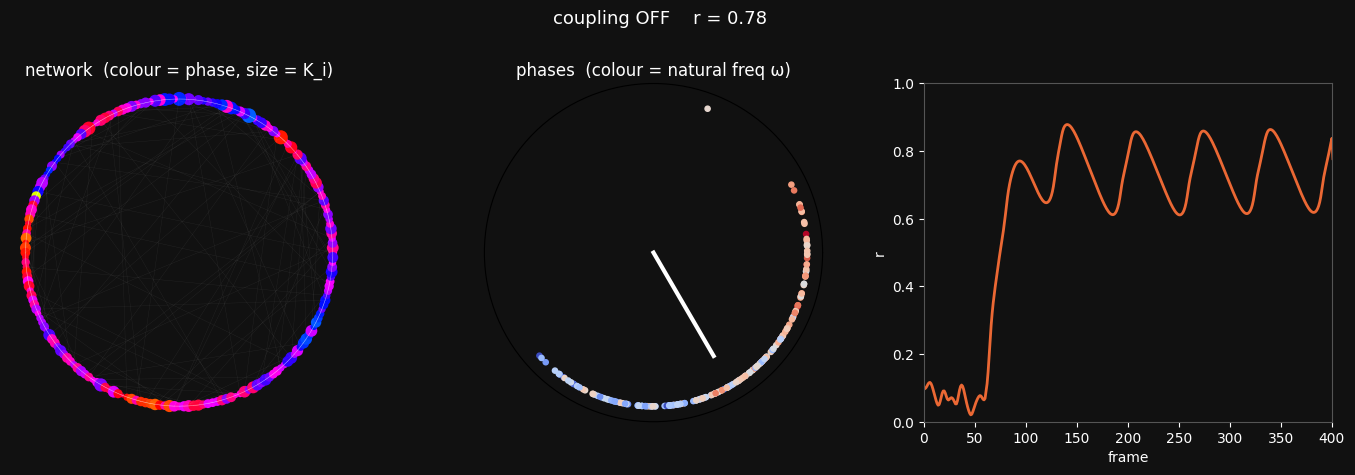

In [ ]:
FRAMES, OFF_FRAMES, SUBSTEPS = 400, 60, 4
theta = rng.uniform(0, 2 * np.pi, N)
pos = np.c_[np.cos(2 * np.pi * np.arange(N) / N), np.sin(2 * np.pi * np.arange(N) / N)]
r_hist = []

fig = plt.figure(figsize=(14, 4.8), facecolor='#111')
ax1 = fig.add_subplot(131); ax2 = fig.add_subplot(132, projection='polar'); ax3 = fig.add_subplot(133)
for a in (ax1, ax2, ax3):
    a.set_facecolor('#111')

for i, j in EDGES:
    ax1.plot(*pos[[i, j]].T, color='white', lw=0.3, alpha=0.08)
nodes = ax1.scatter(pos[:, 0], pos[:, 1], c=theta, cmap='hsv', vmin=0, vmax=2 * np.pi,
                    s=8 + 12 * K_learned, edgecolor='none')
ax1.set_aspect('equal'); ax1.axis('off')
ax1.set_title('network  (colour = phase, size = K_i)', color='w')

dots = ax2.scatter(theta, np.ones(N), c=omega, cmap='coolwarm', s=14, vmin=-2.5, vmax=2.5)
arrow, = ax2.plot([0, 0], [0, 0], color='w', lw=3)
ax2.set_ylim(0, 1.1); ax2.set_yticks([]); ax2.set_xticks([])
ax2.set_title('phases  (colour = natural freq ω)', color='w')

line, = ax3.plot([], [], color='#eb6834', lw=2)
ax3.set_xlim(0, FRAMES); ax3.set_ylim(0, 1)
ax3.set_xlabel('frame', color='w'); ax3.set_ylabel('r', color='w')
ax3.tick_params(colors='w'); [s.set_color('#555') for s in ax3.spines.values()]
title = fig.suptitle('', color='w', fontsize=13)

def update(f):
  global theta
  K = np.zeros(N) if f < OFF_FRAMES else K_learned
  for _ in range(SUBSTEPS):
    theta = step(theta, K)
  th = np.mod(theta, 2 * np.pi)
  z = np.exp(1j * th).mean()
  r_hist.append(abs(z))
  nodes.set_array(th)
  dots.set_offsets(np.c_[th, np.ones(N)])
  arrow.set_data([0, np.angle(z)], [0, abs(z)])
  line.set_data(range(len(r_hist)), r_hist)
  state = 'coupling OFF' if f < OFF_FRAMES else 'selfish coupling ON'
  title.set_text(f'{state}    r = {abs(z):.2f}')
  return nodes, dots, arrow, line, title

anim = FuncAnimation(fig, update, frames=FRAMES, interval=30, blit=False)
plt.tight_layout(rect=[0, 0, 1, 0.9])
anim.save('selfish_kuramoto.gif', fps=30)

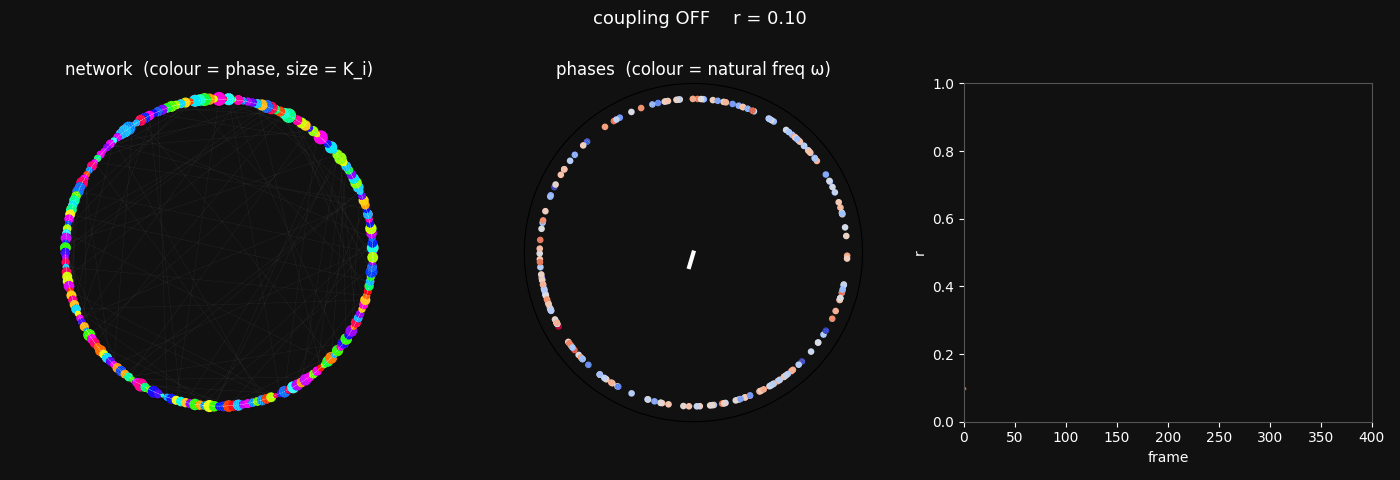

In [ ]:
from IPython.display import Image, display
with open("selfish_kuramoto.gif", 'rb') as f:
    display(Image(data=f.read(), format='png'))